# micrograd — Neuron, Layer, MLP and training loop

Week 1, session 4. The `Value` class below is copied from `derivatives.ipynb` (commit 3320f3a).

In [98]:
import math

class Value:
    def __init__(self, data, _children=(), _op=""):
        self.data = data
        self._prev = set(_children)
        self.grad = 0.0
        self._backward = lambda: None
        self._op = _op

    def __add__(self,other):
        other = other if isinstance(other, Value) else Value(other)
        new_value = self.data + other.data
        out =  Value(new_value,(self,other),"+")

        def _backward():
            self.grad += out.grad
            other.grad += out.grad

        out._backward = _backward
        return out

    def __mul__(self,other):
        other = other if isinstance(other, Value) else Value(other)
        value = self.data * other.data
        out = Value(value, (self,other), "*")

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward
        return out

    def __rmul__(self,other):
       return self * other

    def __radd__(self,other):
        return self + other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def tanh(self):
        out = Value(math.tanh(self.data), (self,), "tanh")

        def _backward():
            self.grad += out.grad * (1 - math.tanh(self.data)**2)
        out._backward = _backward
        return out
        
    def __pow__(self,other):
        assert isinstance(other, (int, float)), "only int/float powers supported"
        out = Value(self.data ** other, (self,), "**")

        def _backward():
            self.grad += out.grad * other * self.data ** (other - 1 )
        out._backward = _backward
        return out
        

    def backward(self):
        visited = set()
        topo = []
        def build(v):
            if v not in visited:
                for child in v._prev:
                    build(child)
                topo.append(v)
                visited.add(v)
        build(self)
        self.grad = 1.0
        for i in reversed(topo):
            i._backward()

    def __repr__(self):
        return f"Value={self.data}"


In [43]:
from viz import draw_dot

In [44]:
x1 = Value(1.0)
x2 = Value(2.0)
wA1 = Value(1.0)
wA2 = Value(1.0)
bA = Value(0.0)
iA = wA1*x1 + wA2*x2 + bA
oA = iA.tanh()

wB1 = Value(1.0)
wB2 = Value(1.0)
bB = Value(0.0)
iB = wB1*x1 + wB2*x2 + bB
oB = iB.tanh()

L = oA + oB
L.backward()

print(wA1.grad)
print(wB1.grad)

0.009866037165440211
0.009866037165440211


In [69]:
import random

class Neuron:
    def __init__(self, nin):
        self.weights = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.bias = Value(random.uniform(-1,1))

    def __call__(self, xs):
        s = Value(0.0)
        for xi, wi in zip(xs, self.weights):
            s += xi*wi
        s += self.bias
        return s.tanh()

    def parameters(self):
        return self.weights + [self.bias]

n = Neuron(3)
n([5.0, 1.0, -3.0])


n = Neuron(3)
n.weights = [Value(1.0), Value(2.0), Value(-1.0)]
n.bias = Value(0.5)
n([0.5, -1.0, 1.0])
print(n.parameters())
            

[Value=1.0, Value=2.0, Value=-1.0, Value=0.5]


In [46]:
print(Value(2.0) * 3.0)     
print(Value(2.0) + 1.0)

n = Neuron(3)
n.weights = [Value(1.0), Value(2.0), Value(-1.0)]
n.bias = Value(0.5)
o = n([0.5, -1.0, 1.0])
o.backward()
print([w.grad for w in n.weights], n.bias.grad)

Value=6.0
Value=3.0
[0.035325412426582214, -0.07065082485316443, 0.07065082485316443] 0.07065082485316443


In [75]:
class Layer:
    def __init__(self,nin,nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        return [neuron(x) for neuron in self.neurons]

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

In [76]:
layer = Layer(3, 4)
out = layer([0.5, -1.0, 1.0])
print(len(out), out)

layer2 = Layer(4, 2)
print(layer2(out))
print(layer2.parameters())

4 [Value=0.9847548315144862, Value=0.23705059441312223, Value=-0.17586572927701305, Value=0.9224300236855607]
[Value=0.9572830044963686, Value=0.10795714611321085]
[Value=0.8398006838656142, Value=-0.8574285942700435, Value=0.06915620367866038, Value=0.7322760499517955, Value=0.6253028221485104, Value=-0.7229693740946868, Value=0.28054977397750336, Value=-0.03385931963722588, Value=0.9774917544198358, Value=-0.15379983469676817]


In [78]:
class MLP:
    def __init__(self, nin, nouts):
        sizes = [nin] + nouts
        self.layers = [Layer(sizes[i], sizes[i+1]) for i in range(len(sizes) - 1)]

    def __call__(self, xs):
        xin = xs
        for layer in self.layers:
            xin = layer(xin)
        return xin

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


mlp = MLP(3, [4, 4, 1])
print([(len(l.neurons), len(l.neurons[0].weights)) for l in mlp.layers])
print(mlp([2.0, 3.0, -1.0]))
print(mlp.parameters(), len(mlp.parameters()))
#draw_dot(mlp([2.0, 3.0, -1.0])[0])

[(4, 3), (4, 4), (1, 4)]
[Value=-0.9038806644727913]
[Value=-0.05679424180201886, Value=0.6248640253592614, Value=-0.7555693268042019, Value=0.8658278308970679, Value=-0.8124714996635773, Value=0.21034110365343395, Value=-0.6902839637520137, Value=0.7890399271912889, Value=-0.2856097023488462, Value=0.6112482540989608, Value=0.4611311271804921, Value=0.963300302300286, Value=0.5959133957117617, Value=-0.32614344651103844, Value=-0.570893185648814, Value=0.14140744419064455, Value=-0.9253936364648869, Value=0.760500101959205, Value=-0.7995281970475725, Value=0.35531046618289985, Value=-0.934239702835288, Value=0.4347233684519176, Value=-0.7588742234653532, Value=-0.7997203569692968, Value=0.22767679245718075, Value=-0.7488507187704316, Value=0.04756257790930252, Value=-0.6056041261614855, Value=0.7283666781987264, Value=0.08703744999032437, Value=0.17549248250848049, Value=0.2157098407196183, Value=0.7169234123147068, Value=-0.46568620273983585, Value=0.27958230512326, Value=-0.61803518

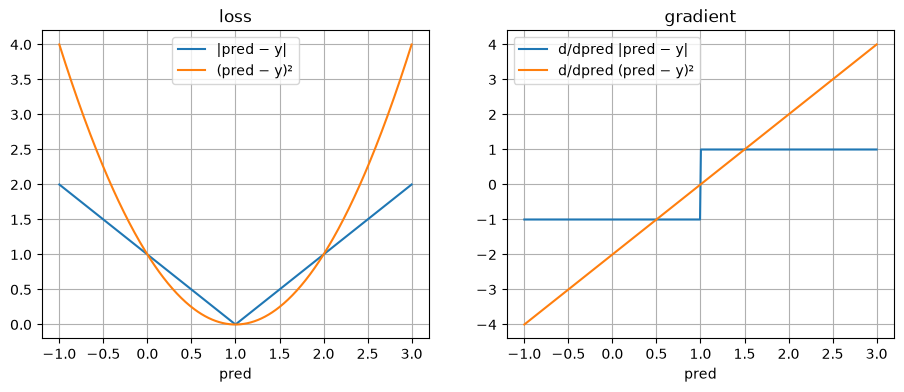

In [79]:
import numpy as np
import matplotlib.pyplot as plt

y = 1.0
pred = np.linspace(-1, 3, 400)
err = pred - y

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(pred, np.abs(err), label="|pred − y|")
ax1.plot(pred, err**2, label="(pred − y)²")
ax1.set_title("loss"); ax1.set_xlabel("pred"); ax1.legend(); ax1.grid()

ax2.plot(pred, np.sign(err), label="d/dpred |pred − y|")
ax2.plot(pred, 2 * err, label="d/dpred (pred − y)²")
ax2.set_title("gradient"); ax2.set_xlabel("pred"); ax2.legend(); ax2.grid()
plt.show()

In [105]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]

mlp = MLP(3, [4, 4, 1])

def forward_mlp(mlp, xs, ys):
    total_loss = 0
    for i, (x,y) in enumerate(zip(xs, ys)):
        pred = mlp(x)
        #print(f"Prediction {i}: {pred}")
        loss = (pred[0] - y)**2
        #print(f"Loss {i}: {loss}")
        total_loss += loss
        
    total_loss.backward()
    print(f"Total loss: {total_loss}")
    
for p in mlp.parameters():
    p.data -= 0.05 * p.grad
    forward_mlp(mlp, xs, ys)
    

Total loss: Value=5.947207811716611
Total loss: Value=5.93994523169512
Total loss: Value=5.903411469121707
Total loss: Value=5.836750065383545
Total loss: Value=5.8321007631611685
Total loss: Value=5.8320622048363
Total loss: Value=5.832002336170038
Total loss: Value=5.830462348884757
Total loss: Value=5.610262235823649
Total loss: Value=5.571927380845863
Total loss: Value=5.123690077110806
Total loss: Value=4.822956024921172
Total loss: Value=4.4929250800489315
Total loss: Value=4.30754396701749
Total loss: Value=4.175041028676045
Total loss: Value=4.175911683804499
Total loss: Value=4.167259183430921
Total loss: Value=4.163046027252602
Total loss: Value=4.1612015343984705
Total loss: Value=4.156087302944428
Total loss: Value=4.149650310523924
Total loss: Value=3.0754023855485775
Total loss: Value=3.021709633188902
Total loss: Value=2.9685207217255662
Total loss: Value=3.1204715598819774
Total loss: Value=3.101484545177436
Total loss: Value=3.3347883939805634
Total loss: Value=1.69613

In [102]:
p = mlp.parameters()[0]
print(p.data, p.grad)

0.9557897872917533 0.06509828171292605
